# 03 · Inspección de una trayectoria y sus eventos

Descompondremos una corrida en registros temporales y distinguiremos los eventos bioquímicos de los pasos mecánicos.

> **ProteinMotorSim 0.1.1** · Ejemplo educativo. Las tasas predeterminadas del modelo son ilustrativas y no representan todavía una parametrización experimental validada.

## Preparación del entorno

Esta celda localiza automáticamente la raíz del repositorio e incorpora `src/` a la ruta de importación. Instala antes las dependencias con `python -m pip install -e ".[dev,viz]"` y selecciona el kernel `Python (ProteinMotorSim)`.

In [1]:
from pathlib import Path
import sys

# Busca la raíz del proyecto desde el directorio actual o sus carpetas padre.
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in _candidates if (path / "pyproject.toml").exists() and (path / "src").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "No se encontró ProteinMotorSim. Abre JupyterLab desde la carpeta raíz "
        "del proyecto o desde su carpeta notebooks/."
    )

sys.path.insert(0, str(PROJECT_ROOT / "src"))
print(f"Proyecto detectado: {PROJECT_ROOT}")

Proyecto detectado: /home/zix/ProteinMotorSim


In [2]:
import matplotlib.pyplot as plt

from protein_motor_sim import Environment, GillespieSimulator, Kinesin1

trajectory = GillespieSimulator().run(
    Kinesin1(), Environment(atp_concentration=1.0e-3), t_max=0.25, seed=7
)

## 1. Mostrar los registros

In [3]:
print(f"{'i':>3} {'t (s)':>12} {'x (nm)':>12} {'estado':>20} {'evento':>22}")
for i, (time_s, position_nm, state, event) in enumerate(zip(
    trajectory.times_s, trajectory.positions_nm, trajectory.states, trajectory.events
)):
    print(f"{i:3d} {time_s:12.6f} {position_nm:12.3f} {state:>20} {event:>22}")

  i        t (s)       x (nm)               estado                 evento
  0     0.000000        0.000            bound_apo                initial
  1     0.000470        0.000            atp_bound            atp_binding
  2     0.003637        0.000      post_hydrolysis         atp_hydrolysis
  3     0.015641        8.200            bound_apo           forward_step
  4     0.020887        8.200            atp_bound            atp_binding
  5     0.023715        8.200      post_hydrolysis         atp_hydrolysis
  6     0.035624       16.400            bound_apo           forward_step
  7     0.036991       16.400            atp_bound            atp_binding
  8     0.045521       16.400      post_hydrolysis         atp_hydrolysis
  9     0.045566       24.600            bound_apo           forward_step
 10     0.046040       24.600            atp_bound            atp_binding
 11     0.065188       24.600      post_hydrolysis         atp_hydrolysis
 12     0.070077       32.800         

## 2. Posición y tiempos de evento

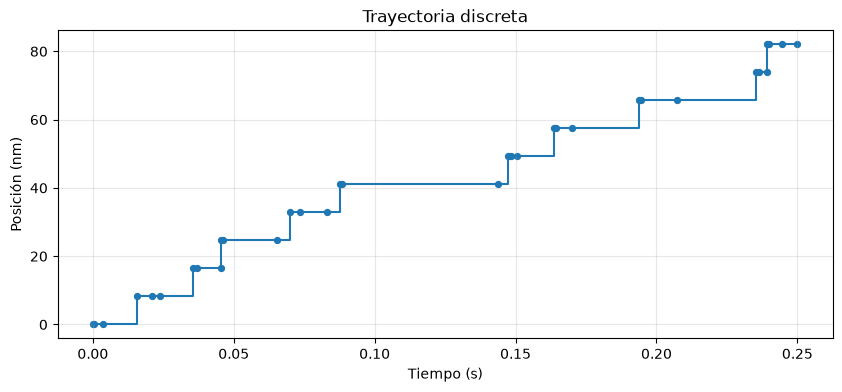

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.step(trajectory.times_s, trajectory.positions_nm, where="post")
ax.scatter(trajectory.times_s, trajectory.positions_nm, s=18)
ax.set(xlabel="Tiempo (s)", ylabel="Posición (nm)", title="Trayectoria discreta")
ax.grid(alpha=0.3)
plt.show()

## 3. Contar eventos

In [5]:
from collections import Counter

counts = Counter(event for event in trajectory.events if event != "initial")
for event, count in sorted(counts.items()):
    print(f"{event:22s}: {count}")

atp_binding           : 11
atp_hydrolysis        : 11
forward_step          : 10
observation_end       : 1


## 4. Distinguir desplazamiento neto y longitud de camino

In [6]:
print("Desplazamiento neto (nm):", trajectory.displacement_nm)
print("Longitud total del camino (nm):", trajectory.path_length_nm)
print("Duración observada (s):", trajectory.duration_s)
print("Velocidad neta media (nm/s):", trajectory.mean_velocity_nm_s)

Desplazamiento neto (nm): 82.00000000000001
Longitud total del camino (nm): 82.00000000000001
Duración observada (s): 0.25
Velocidad neta media (nm/s): 328.00000000000006


**Interpretación:** el desplazamiento neto considera la diferencia entre las posiciones final e inicial. La longitud total suma los módulos de todos los cambios de posición, por lo que también cuenta los retrocesos.